# Is That Your Final Answer? What Label Smoothing Does to an Overconfident CNN

*By Gabriel Mar Ramirez · Deep Learning portfolio · November 2026*

Every online match has *that* teammate: "Enemy's mid. Trust me bro, 100%." When they're wrong, they're wrong **loudly**, and you're the one who walks into the ambush.

Neural networks can be that teammate: normal training rewards sounding ever more sure, even when wrong. **Label smoothing** is a one-line fix that tells the network *never claim 100%*, like a game-show host asking "Is that your final answer?" before every lock-in.

> **The question:** if I train the same small CNN on Fashion-MNIST with label smoothing ε = 0, 0.05, 0.1, 0.2 and 0.3, what happens to its accuracy, and to how confident it is when it's right versus when it's wrong?

**Spoiler:** accuracy barely moved, but confidence changed a lot, and too much smoothing created the opposite teammate: one who says "uhh, maybe?" even when right.

## 1. How a classifier "answers"

Picture each prediction as a quiz show where the model splits **100 points** of belief across the 10 clothing types. Under the hood, the network outputs 10 raw scores (**logits**) and **softmax** turns them into percentages summing to 100%. Its answer is the class with the most points, and that share is its **confidence**.

Training grades each answer with the **cross-entropy loss**:

$$\mathcal{L} = -\log p_y$$

where $p_y$ is the share the model put on the correct class $y$. Putting 90% on the right answer costs a little (0.11); putting 10% costs a lot (2.30).

The catch: the usual **one-hot** target is "put 100% on the right answer," and the penalty only reaches zero at exactly 100%. So even after the model is right, training keeps pushing it to be *more* sure. Hello, "trust me bro" model.

## 2. Label smoothing: "Is that your final answer?"

Label smoothing (Szegedy et al., 2016) changes the target from "all in" to "**mostly in**." With ε = 0.1, a Sneaker's target becomes 91% Sneaker and 1% for each of the other nine classes:

$$\text{target}_k = (1-\varepsilon)\,\mathbf{1}[k = y] + \frac{\varepsilon}{K}$$

In words: take a fraction ε away from the correct class and share it equally among all $K = 10$ classes. ($\mathbf{1}[k=y]$ just means 1 for the correct class, 0 for the others.) **ε is the hyperparameter**: the bigger it is, the more modest the model is told to be.

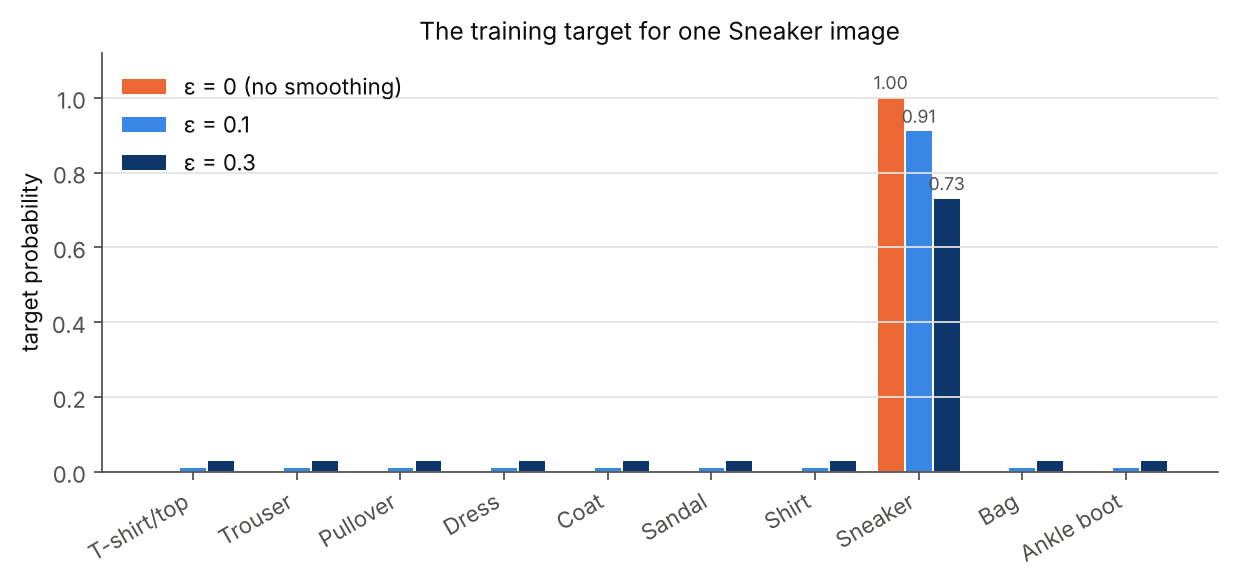

*__Figure 1.__ The target for one Sneaker image. Raising ε lowers how sure the model is asked to be: 100% → 91% → 73%.*

### Is the model honest about how sure it is?

Think of a weather forecast. If it says "70% chance of rain" on 10 days, it should rain on about 7 of them. A classifier is **calibrated** when its confidence works the same way: when it says 80%, it's right about 80% of the time.

- **Overconfident:** says 95%, right 85% of the time (the "trust me bro" teammate).
- **Underconfident:** says 60%, right 95% of the time (the teammate who whispers "maybe?" while staring at the enemy).

I measure this two ways:

- **Reliability diagram:** group predictions by confidence (15 groups) and plot how often each group was actually right. An honest model sits on the diagonal.
- **ECE (expected calibration error):** the average gap between "how sure it said it was" and "how often it was right" (Guo et al., 2017). 0% is perfectly honest.

Müller et al. (2019) found label smoothing usually keeps accuracy and makes models more honest. I put that to the test.

### A gotcha: smoothed scores have a floor

In [1]:
import torch

eps, K = 0.1, 10
target = torch.full((K,), eps / K)
target[7] += 1 - eps                     # class 7 = Sneaker
floor = -(target * target.log()).sum()   # the lowest loss this target allows
print(target)
print(f"loss floor at eps={eps}: {floor:.3f}")

tensor([0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.0100, 0.9100, 0.0100,
        0.0100])
loss floor at eps=0.1: 0.500


Even a perfect model can't score below 0.50 on the smoothed loss at ε = 0.1 (1.18 at ε = 0.3). Comparing those would be like comparing scores from games with different rules, so **every loss in this post is the plain cross-entropy**.

## 3. The experiment: one knob, five settings

Starting from the class notebook `hyperparameters_lightning.ipynb`, I changed exactly **one** thing between runs: ε.

| Setting | Value |
|---|---|
| Dataset | Fashion-MNIST (`torchvision.datasets`): 28×28 grayscale clothing images, 10 classes |
| Training data | 10,000-image subset, to keep runs short |
| Validation data | 6,000 images (10% of the training split), used for **every** comparison; test set unused |
| Model | class `SmallCNN`: two conv blocks (32, 64 channels), batch norm, ReLU, dropout 0.25, 128-unit hidden layer; **421,834 parameters** |
| Optimizer | Adam, learning rate 0.001 |
| Batch size | 64 |
| Epochs | 15 for every run (no early stopping) |
| Seed | 42 (main runs); 43 and 44 to check for luck |
| **What changes** | **label smoothing ε ∈ {0, 0.05, 0.1, 0.2, 0.3}** |

The only code that differs between runs:

```python
# training step: the one line that changes between runs
loss = F.cross_entropy(logits, y, label_smoothing=self.hp.label_smoothing)

# validation step: always the plain cross-entropy, so runs stay comparable
val_loss = F.cross_entropy(logits, y)
```

The full notebook reproduces every figure and table here: [on GitHub](https://github.com/YOUR-GITHUB-USERNAME/label-smoothing-blog/blob/main/label_smoothing_experiment.ipynb) · [open in Colab](https://colab.research.google.com/github/YOUR-GITHUB-USERNAME/label-smoothing-blog/blob/main/label_smoothing_experiment.ipynb).

## 4. Results

### Learning curves

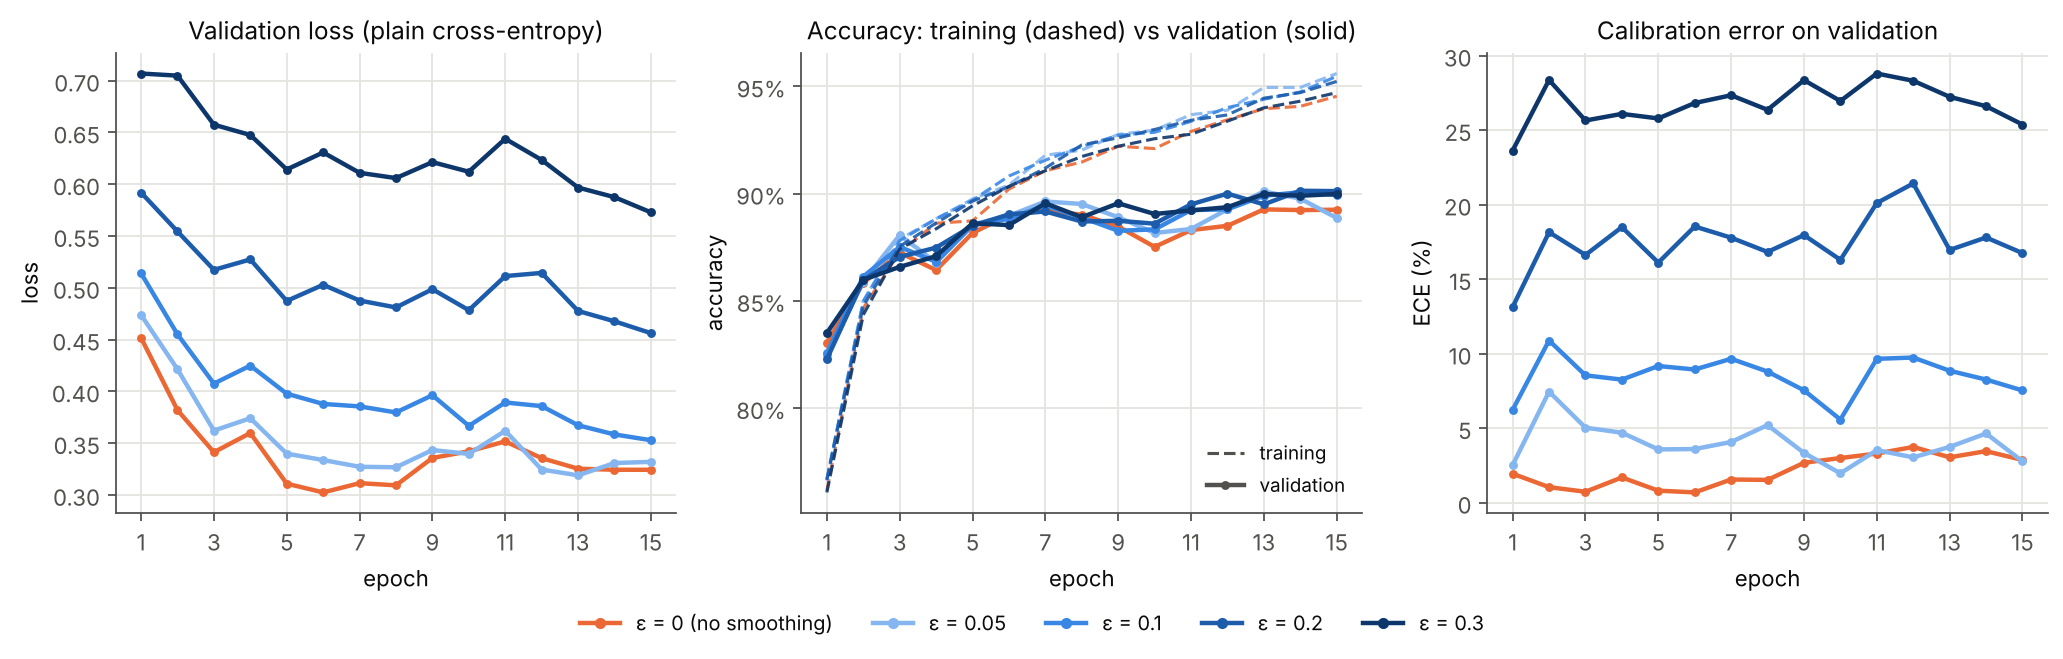

*__Figure 2.__ Learning curves for seed 42 (loss is plain cross-entropy).* **What it shows:** all five settings reach 89–90% validation accuracy, but their losses and calibration errors separate early and stay apart.

The baseline (orange) bottoms out at 0.302 validation loss at epoch 6, then drifts to 0.352 by epoch 11 as training accuracy climbs to 94.5%: it's getting cocky.

### Calibration: who's honest about their confidence?

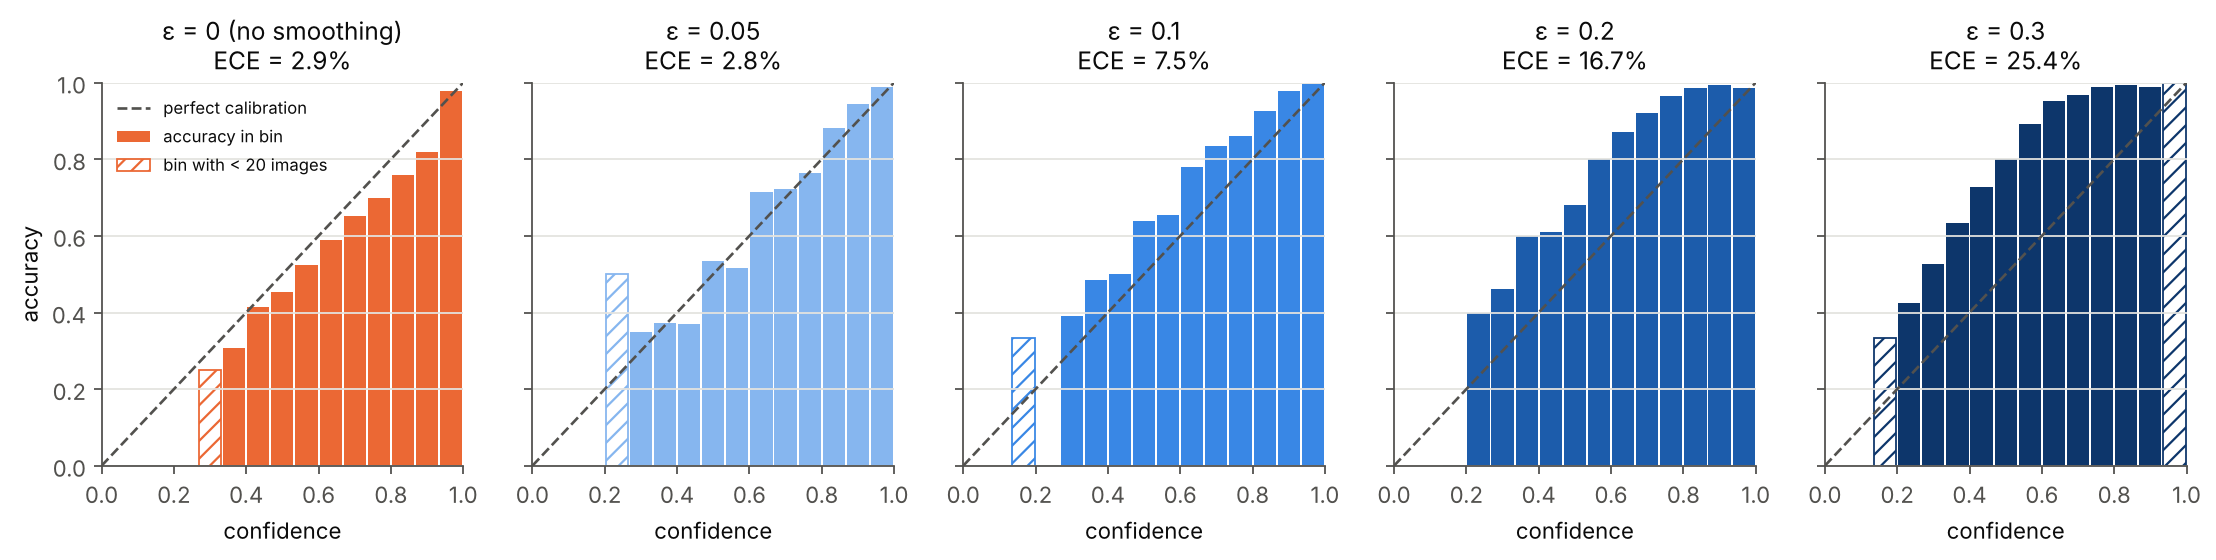

*__Figure 3.__ Reliability diagrams, seed 42, epoch 15. Hatched bins hold under 20 images.* **What it shows:** without smoothing, the bars sit slightly *below* the diagonal (overconfident); with ε ≥ 0.1 they sit clearly *above* it (underconfident).

### The "trust me bro" meter

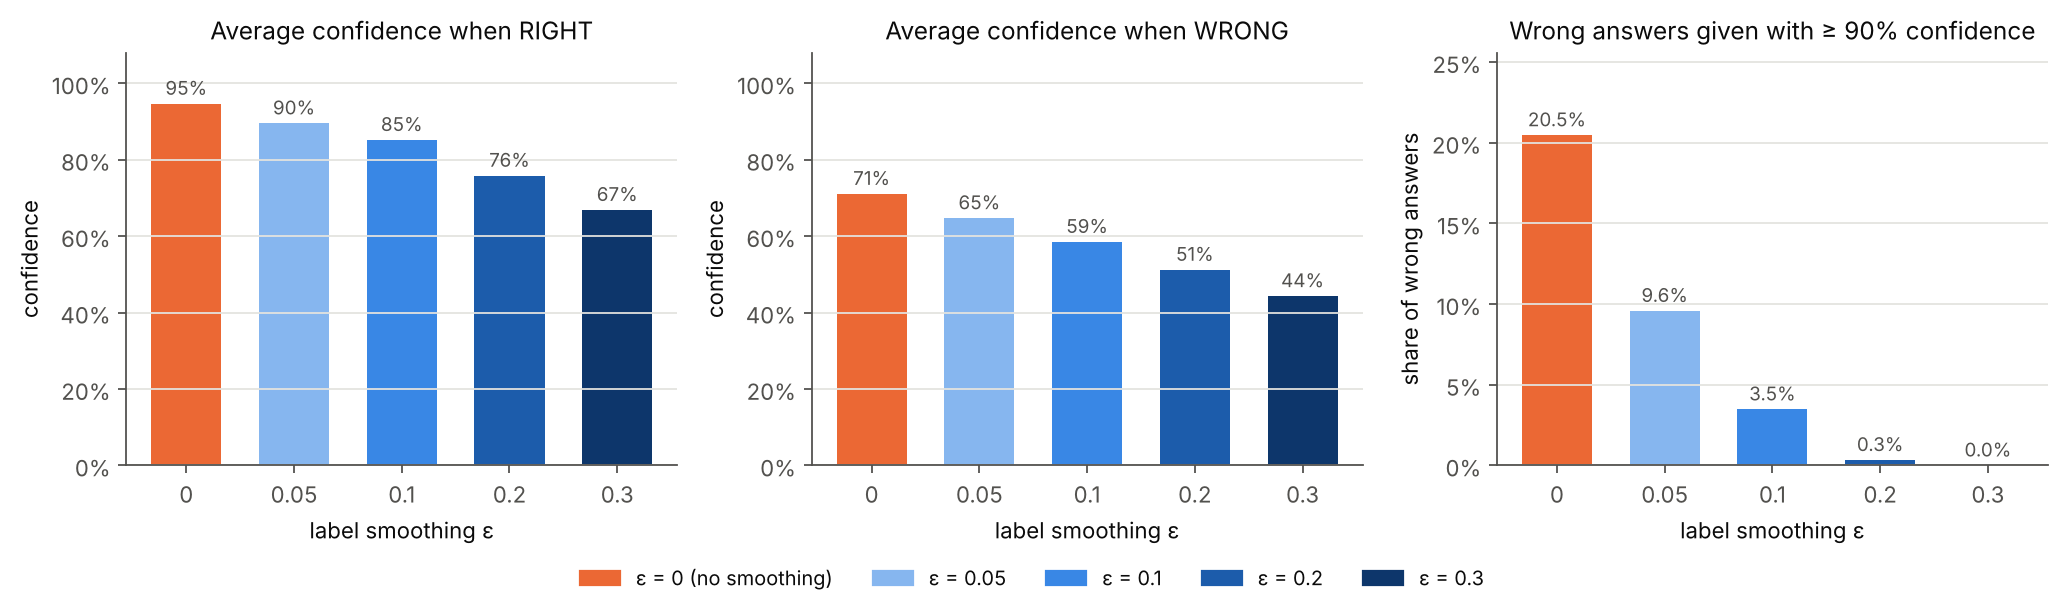

*__Figure 4.__ The "trust me bro" meter, seed 42, epoch 15.* **What it shows:** smoothing lowers confidence on *every* answer; confident mistakes drop from 132 of 645 (20.5%) at ε = 0 to 21 of 604 (3.5%) at ε = 0.1.

**Table 1.** Final-epoch results, seed 42.

| ε | Val accuracy | Val loss | ECE | Confidence − accuracy | Mistakes with ≥ 90% confidence |
|---|---|---|---|---|---|
| 0 | 89.25% | 0.324 | 2.9% | +2.9 pts | 20.5% |
| 0.05 | 88.87% | 0.332 | 2.8% | −2.1 pts | 9.6% |
| 0.1 | 89.93% | 0.353 | 7.5% | −7.4 pts | 3.5% |
| 0.2 | 90.12% | 0.456 | 16.7% | −16.7 pts | 0.3% |
| 0.3 | 89.98% | 0.573 | 25.4% | −25.4 pts | 0.0% |

**Table 2.** Is it luck? Seeds 42, 43 and 44 (mean ± standard deviation, final epoch).

| ε | Val accuracy | ECE | Confidence − accuracy |
|---|---|---|---|
| 0 | 89.3 ± 0.6% | 3.7 ± 1.6% | +3.7 pts |
| 0.05 | 89.6 ± 0.7% | 2.9 ± 0.1% | −2.6 pts |
| 0.1 | 89.8 ± 0.3% | 7.0 ± 1.1% | −7.0 pts |
| 0.2 | 90.2 ± 0.1% | 17.3 ± 0.9% | −17.3 pts |
| 0.3 | 90.3 ± 0.4% | 26.2 ± 0.8% | −26.2 pts |

**What the tables show:** the pattern holds across seeds. Accuracy moves about one point; the confidence gap swings from +3.7 to −26.2 points.

## 5. What happened, and why

**Did the results match the theory?** Partly.

-  **Accuracy stayed about the same**, as Müller et al. (2019) found. It rose from 89.3% to 90.3%, within seed noise (spread up to 0.7 points).
-  **Fewer confidently wrong answers**, exactly what "never say 100%" should do. At ε = 0.1, average confidence on mistakes fell from 71% to 59%.
-  **Calibration improved only at ε = 0.05** (average ECE 3.7% → 2.9%). Every larger ε made it *worse*, up to 26.2%.

**Why did more smoothing backfire?** My "trust me bro" teammate wasn't very overconfident to begin with: confidence was only 2.9 points above accuracy. Guo et al. (2017) found bigger models are more overconfident, and our CNN is tiny. So smoothing had little to fix, and it overcorrected. At ε = 0.3, predictions made with 60–67% confidence are right 95% of the time (Figure 3). The host asked "Is that your final answer?" so often that the contestant stopped trusting answers they knew.

Validation loss agrees: it rose with ε (0.324 → 0.573) because plain cross-entropy punishes doubting correct answers. Thulasidasan et al. (2019) also found ε = 0.05–0.1 best; their appendix even shows ε = 0.1 raising a CIFAR-10 ResNet-18's ECE from 2.3% to 8.9%.

**Limitations of this experiment:**

1. **One small model, short training** (10,000 images, 15 epochs). Bigger, longer-trained networks are more overconfident; smoothing may help more there.
2. **Only three seeds**, and the seed also changed the validation split, so ~1-point accuracy differences are within noise.
3. **ECE is rough:** it depends on the number of groups (15 here) and is noisy in near-empty ones. I also skipped temperature scaling, a simple after-training fix.

## 6. Takeaways

1. **Label smoothing is a confidence knob, not an accuracy knob.** Accuracy moved about 1 point; the confidence gap moved about 30.
2. **Check for overconfidence *before* smoothing.** Here ε = 0.05 helped; ε ≥ 0.1 made the model clearly underconfident.
3. **Compare runs with plain cross-entropy**, never the smoothed loss, whose floor makes curves incomparable.

## References

- Szegedy, C., et al. (2016). *Rethinking the Inception Architecture for Computer Vision.* CVPR. https://arxiv.org/abs/1512.00567
- Müller, R., Kornblith, S., & Hinton, G. (2019). *When Does Label Smoothing Help?* NeurIPS. https://arxiv.org/abs/1906.02629
- Guo, C., et al. (2017). *On Calibration of Modern Neural Networks.* ICML. https://arxiv.org/abs/1706.04599
- Thulasidasan, S., et al. (2019). *On Mixup Training: Improved Calibration and Predictive Uncertainty for Deep Neural Networks.* NeurIPS. https://arxiv.org/abs/1905.11001
- Xiao, H., Rasul, K., & Vollgraf, R. (2017). *Fashion-MNIST: a Novel Image Dataset for Benchmarking Machine Learning Algorithms.* https://arxiv.org/abs/1708.07747
- PyTorch docs, `torch.nn.CrossEntropyLoss`. https://docs.pytorch.org/docs/stable/generated/torch.nn.CrossEntropyLoss.html
- Class notebook `hyperparameters_lightning.ipynb`: my experiment reuses its data module, model, config and `fit()` helper.

---

*AI-use note: I used Claude (Anthropic) to brainstorm the topics and experiment, to help write and debug the experiment code built on the class notebook, and to proofread this post.*